# 06 — Model B: Cross-Period Next-Day AQI Forecasting

## Objective

This notebook evaluates whether AQI-only models trained on historical Indian air-quality observations from **2015–2020** can predict next-day AQI during **2024–2025**.

To assess cross-period generalization, Ridge Regression, Random Forest, and Histogram Gradient Boosting are trained on historical observations and compared with a persistence baseline. Equivalent models trained on recent observations from **2023–2024** are then evaluated on the **same held-out test rows**.

All models use identical AQI-based and calendar features to ensure comparable evaluation across training periods.

**Datasets:** `data/Cleaned/city_day_clean.csv` and `data/Cleaned/aqi_2023_2025_clean.csv`

**Evaluation:** 3,604 held-out observations across 23 common cities, with target dates from 1 November 2024 to 30 April 2025.

The experiment examines temporal transferability rather than same-day pollutant-based AQI estimation.

## 1. Imports, settings and reproducibility

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'Cleaned'
FIGURES = ROOT / 'reports' / 'figures' / 'model_b'
RESULTS = ROOT / 'reports' / 'results' / 'modelb'
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

# File paths verified from the uploaded notebooks. Edit these if your repo differs.
OLD_CSV = DATA / 'city_day_clean.csv'
NEW_CSV = DATA / 'aqi_2023_2025_clean.csv'
# A valid alternative to NEW_CSV is a daily City/Date/AQI CSV.
RECENT_TRAIN_START = '2023-01-01'
RECENT_TEST_START = '2024-11-01'  # follows the in-period evaluation window
RECENT_TEST_END = '2025-04-30'
HISTORICAL_END = '2020-12-31'

print('Project root:', ROOT)
for p in [OLD_CSV, NEW_CSV]:
    print(('FOUND' if p.exists() else 'MISSING'), p)
if not (OLD_CSV.exists() and NEW_CSV.exists()):
    raise FileNotFoundError('Place both cleaned CSVs at the paths shown above, then rerun. Do not substitute pre-generated feature tables.')

Project root: d:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India
FOUND d:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\data\Cleaned\city_day_clean.csv
FOUND d:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\data\Cleaned\aqi_2023_2025_clean.csv


## 2. Load Historical and Recent Datasets

The historical dataset contains city-level AQI observations and pollutant measurements, while the recent dataset contains daily AQI values and prominent pollutant labels.

For comparability, this experiment uses only **City, Date, and AQI** from each source. Pollutant measurements are excluded because their availability and definitions differ.

The historical dataset is derived from the earlier `city_day.csv` processing workflow, while the recent dataset is produced by the AQI cleaning notebook.

In [11]:
old_raw = pd.read_csv(OLD_CSV, low_memory=False)
new_raw = pd.read_csv(NEW_CSV, low_memory=False)
print('Historical raw shape:', old_raw.shape)
print('Recent raw shape:', new_raw.shape)
print('Old columns:', list(old_raw.columns))
print('New columns:', list(new_raw.columns))

Historical raw shape: (24801, 23)
Recent raw shape: (235005, 7)
Old columns: ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI', 'AQI_Bucket', 'Year', 'Month', 'Day', 'Weekday', 'Is_Weekend', 'Season', 'Is_Winter', 'Is_Diwali_Period']
New columns: ['Date', 'state', 'City', 'number_of_monitoring_stations', 'prominent_pollutants', 'AQI', 'AQI_Bucket']


## 3. Data Standardization and Geographic Coverage

City names, dates, and numerical AQI values are standardized across both datasets. Invalid observations are excluded, and duplicate city-date records are consolidated using median AQI.

After preprocessing:

- **Historical:** 24,258 observations across 26 cities, January 2015 – July 2020.
- **Recent:** 191,718 observations across 290 cities, January 2023 – April 2025.
- **Geographic overlap:** 25 cities occur in both datasets.

Subsequent experiments retain only cities represented in the required training and evaluation partitions.

In [12]:
# Add only verified or explicitly reviewed spelling aliases, not fuzzy-matched guesses.
CITY_ALIASES = {
    'Gurgaon': 'Gurugram',
    'New Delhi': 'Delhi',
    'Bangalore': 'Bengaluru',
}

def normalize(raw, source):
    rename = {'area':'City', 'city':'City', 'date':'Date', 'aqi_value':'AQI', 'aqi':'AQI'}
    d = raw.rename(columns={k:v for k,v in rename.items() if k in raw and v not in raw}).copy()
    required = {'City','Date','AQI'}
    if not required.issubset(d.columns):
        raise ValueError(f'{source}: missing columns {required - set(d.columns)}')
    d = d[['City','Date','AQI']].copy()
    # Explicit format handling avoids mixing day/month order without inspection.
    dt_iso = pd.to_datetime(d['Date'], format='%Y-%m-%d', errors='coerce')
    dt_dmy = pd.to_datetime(d['Date'], format='%d-%m-%Y', errors='coerce')
    d['Date'] = dt_iso if dt_iso.notna().sum() >= dt_dmy.notna().sum() else dt_dmy
    d['Date'] = d['Date'].dt.normalize()
    d['City'] = d['City'].astype('string').str.strip().str.title().replace(CITY_ALIASES)
    d['AQI'] = pd.to_numeric(d['AQI'], errors='coerce')
    d = d.dropna(subset=['City','Date','AQI']).copy()
    d = d[d['AQI'].between(0, 500)]  # CPCB-index domain; review out-of-range exclusions
    duplicates = d.duplicated(['City','Date'], keep=False).sum()
    if duplicates:
        print(f'{source}: {duplicates} duplicate city-date rows; using median AQI per city-date')
    d = d.groupby(['City','Date'], as_index=False)['AQI'].median()
    d['source'] = source
    return d.sort_values(['City','Date']).reset_index(drop=True)

old = normalize(old_raw, 'historical_2015_2020')
new = normalize(new_raw, 'recent_2023_2025')
old = old[old['Date'] <= pd.Timestamp(HISTORICAL_END)].copy()
new = new[new['Date'] >= pd.Timestamp(RECENT_TRAIN_START)].copy()

for name,d in [('Historical',old),('Recent',new)]:
    print(name, 'rows:',len(d),'cities:',d.City.nunique(), 'dates:',d.Date.min(), 'to',d.Date.max())

common_cities = sorted(set(old.City) & set(new.City))
print('Overlapping cities:',len(common_cities))
print('Examples:',common_cities[:30])
if not common_cities:
    raise ValueError('No shared cities: inspect city spelling and revise CITY_ALIASES after validating mappings.')
old = old[old.City.isin(common_cities)].copy()
new = new[new.City.isin(common_cities)].copy()

Historical rows: 24258 cities: 26 dates: 2015-01-01 00:00:00 to 2020-07-01 00:00:00
Recent rows: 191718 cities: 290 dates: 2023-01-01 00:00:00 to 2025-04-30 00:00:00
Overlapping cities: 25
Examples: ['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


## 4. Shared, leakage-safe daily feature engineering

At each date **t**, `AQI` is the observed current-day AQI, and the target is **AQI(t+1)**. Previous-day lags and rolling statistics are built from a city-specific daily grid, so absent dates remain `NaN` rather than becoming the previous row. No future target is used as a feature. Date features are defined identically across datasets. Festival and pollutant features are **intentionally excluded** because comparable measurements are not guaranteed across both sources.

**Operational assumption:** today's finalized AQI is available when forecasting tomorrow. If you need an early-morning forecast, change that assumption and remove same-day AQI.

In [13]:
NUMERIC = ['AQI','AQI_lag1','AQI_lag2','AQI_lag3','AQI_lag7',
           'AQI_roll3','AQI_roll7','AQI_roll14','AQI_std7','AQI_change1',
           'month','weekday','is_weekend','is_winter']
CATEGORICAL = ['City','season']
FEATURES = NUMERIC + CATEGORICAL

def make_aqi_features(d):
    pieces = []
    for city, group in d.groupby('City', sort=True):
        group = group.sort_values('Date').set_index('Date')
        # Daily calendar prevents treating missing days as consecutive observations.
        daily = group[['AQI']].reindex(pd.date_range(group.index.min(),group.index.max(),freq='D'))
        daily.index.name = 'Date'
        daily['City'] = city
        for lag in (1,2,3,7):
            daily[f'AQI_lag{lag}'] = daily['AQI'].shift(lag)
        for w in (3,7,14):
            daily[f'AQI_roll{w}'] = daily['AQI'].shift(1).rolling(w,min_periods=max(2,int(w*0.7))).mean()
        daily['AQI_std7'] = daily['AQI'].shift(1).rolling(7,min_periods=5).std()
        daily['AQI_change1'] = daily['AQI'] - daily['AQI_lag1']
        daily['target_AQI_next'] = daily['AQI'].shift(-1)
        daily['target_date'] = daily.index + pd.Timedelta(days=1)
        daily['month'] = daily.index.month
        daily['weekday'] = daily.index.dayofweek
        daily['is_weekend'] = (daily['weekday'] >= 5).astype(int)
        daily['is_winter'] = daily['month'].isin([11,12,1,2]).astype(int)
        daily['season'] = np.select(
            [daily['month'].isin([12,1,2]), daily['month'].isin([3,4,5]),
             daily['month'].isin([6,7,8,9])],
            ['Winter','Summer','Monsoon'], default='Post-Monsoon')
        pieces.append(daily.reset_index())
    result = pd.concat(pieces,ignore_index=True)
    required = NUMERIC + ['target_AQI_next']
    result = result.dropna(subset=required).copy()
    return result.sort_values(['Date','City']).reset_index(drop=True)

historical_features = make_aqi_features(old)
recent_features = make_aqi_features(new)
print('Historical usable features:',len(historical_features))
print('Recent usable features:',len(recent_features))
display(historical_features[['City','Date','AQI','AQI_lag1','AQI_roll7','target_AQI_next']].head())

# Spot-check temporal alignment on sampled rows from BOTH datasets.
for label,source,features in [('historical',old,historical_features),('recent',new,recent_features)]:
    sampled = features.sample(min(200,len(features)),random_state=SEED)
    look = source.set_index(['City','Date'])['AQI']
    for r in sampled.itertuples(index=False):
        assert np.isclose(r.target_AQI_next,look.loc[(r.City,r.Date+pd.Timedelta(days=1))])
        assert np.isclose(r.AQI_lag1,look.loc[(r.City,r.Date-pd.Timedelta(days=1))])
    print(label,': temporal spot-check passed',len(sampled),'rows')

Historical usable features: 20793
Recent usable features: 16590


,City,Date,AQI,AQI_lag1,AQI_roll7,target_AQI_next
0,Delhi,2015-01-10,376.0,375.0,316.571429,379.0
1,Delhi,2015-01-11,379.0,376.0,349.857143,375.0
2,Delhi,2015-01-12,375.0,379.0,358.428571,366.0
3,Delhi,2015-01-13,366.0,375.0,365.571429,353.0
4,Delhi,2015-01-14,353.0,366.0,372.428571,340.0


historical : temporal spot-check passed 200 rows
recent : temporal spot-check passed 200 rows


## 5. Chronological Evaluation and Matched Test Cohort

The experiment uses three non-overlapping partitions:

| Partition | Observations | Coverage |
|---|---:|---|
| Historical training | 20,112 | 2015–2020 |
| Recent training | 12,753 | 2023–October 2024 |
| Common held-out test | 3,604 | November 2024–April 2025 |

All three partitions contain **23 common cities**.

Historical-trained and recent-trained models use the same feature definitions and are evaluated against identical next-day AQI targets. This design isolates differences associated with the training period while holding the evaluation cohort constant.

The training sets differ in sample size and AQI distribution, so the comparison does not independently isolate temporal change from other dataset differences.

In [14]:
test_start = pd.Timestamp(RECENT_TEST_START)
test_end = pd.Timestamp(RECENT_TEST_END)
historical_train = historical_features[historical_features['target_date'] <= pd.Timestamp(HISTORICAL_END)].copy()
recent_train = recent_features[recent_features['target_date'] < test_start].copy()
test = recent_features[recent_features['target_date'].between(test_start,test_end)].copy()
valid_cities = set(historical_train.City) & set(recent_train.City) & set(test.City)
historical_train = historical_train[historical_train.City.isin(valid_cities)].copy()
recent_train = recent_train[recent_train.City.isin(valid_cities)].copy()
test = test[test.City.isin(valid_cities)].copy()
if min(len(historical_train),len(recent_train),len(test)) == 0:
    raise ValueError('One split is empty. Inspect dataset date coverage, CITY_ALIASES and test window.')
assert historical_train['target_date'].max() < recent_train['target_date'].min()
assert recent_train['target_date'].max() < test['target_date'].min()
assert not test.duplicated(['City','Date']).any()
for label,frame in [('Historical train',historical_train),('Recent train',recent_train),('Common test',test)]:
    print(f'{label}: {len(frame):,} rows; {frame.City.nunique()} cities; target dates',
          frame.target_date.min().date(),'to',frame.target_date.max().date())
print('Common cities:',sorted(valid_cities))

Historical train: 20,112 rows; 23 cities; target dates 2015-01-11 to 2020-07-01
Recent train: 12,753 rows; 23 cities; target dates 2023-01-11 to 2024-10-31
Common test: 3,604 rows; 23 cities; target dates 2024-11-01 to 2025-04-30
Common cities: ['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


## 6. Train persistence, Ridge, Random Forest and HistGradientBoosting

In [15]:
def make_encoder():
    # Handle older versions of scikit-learn that use sparse= rather than sparse_output=.
    try: return OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError: return OneHotEncoder(handle_unknown='ignore',sparse=False)

def make_preprocessor(scale=False):
    numeric_steps = [('imputer',SimpleImputer(strategy='median'))]
    if scale: numeric_steps.append(('scaler',StandardScaler()))
    return ColumnTransformer([
        ('num',Pipeline(numeric_steps),NUMERIC),
        ('cat',make_encoder(),CATEGORICAL)
    ],remainder='drop')

def make_models():
    return {
        'Ridge Regression':Pipeline([('pre',make_preprocessor(True)),('model',Ridge(alpha=1.0))]),
        'Random Forest':Pipeline([('pre',make_preprocessor()),('model',RandomForestRegressor(
            n_estimators=150,min_samples_leaf=5,max_features=0.8,n_jobs=-1,random_state=SEED))]),
        'Hist Gradient Boosting':Pipeline([('pre',make_preprocessor()),('model',HistGradientBoostingRegressor(
            max_iter=180,random_state=SEED))]),
    }

def evaluate(y,pred,name,training_period):
    return {'Training':training_period,'Model':name,
            'MAE':mean_absolute_error(y,pred),
            'RMSE':float(np.sqrt(mean_squared_error(y,pred))),
            'R2':r2_score(y,pred)}

actual = test['target_AQI_next'].to_numpy()
predictions = pd.DataFrame({'City':test.City.to_numpy(), 'Date':test.Date.to_numpy(),
                            'target_date':test.target_date.to_numpy(),'actual':actual})
results = []
predictions['Persistence'] = test['AQI'].to_numpy()
results.append(evaluate(actual,predictions['Persistence'],'Persistence (tomorrow = today)','No fitting'))

historical_fitted = {}
for name,model in make_models().items():
    model.fit(historical_train[FEATURES], historical_train['target_AQI_next'])
    p = model.predict(test[FEATURES])
    predictions['Historical - '+name] = p
    results.append(evaluate(actual,p,name,'Historical 2015–2020'))
    historical_fitted[name] = model
    print('Completed historical:',name)

display(pd.DataFrame(results).round(3))

Completed historical: Ridge Regression
Completed historical: Random Forest
Completed historical: Hist Gradient Boosting


,Training,Model,MAE,RMSE,R2
0,No fitting,Persistence (tomorrow = today),24.270,35.826,0.769
1,Historical 2015–2020,Ridge Regression,23.336,33.477,0.798
2,Historical 2015–2020,Random Forest,23.458,33.569,0.797
3,Historical 2015–2020,Hist Gradient Boosting,23.210,33.363,0.800


## 7. Historical Model Evaluation

Historical-trained models are evaluated using MAE, RMSE, and R² on the common held-out test cohort.

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Histogram Gradient Boosting | 23.210 | 33.363 | 0.800 |
| Ridge Regression | 23.336 | 33.477 | 0.798 |
| Random Forest | 23.458 | 33.569 | 0.797 |
| Persistence | 24.270 | 35.826 | 0.769 |

Histogram Gradient Boosting is the strongest historical-trained model, improving MAE over persistence by approximately **4.4%**.

All three historical-trained models outperform persistence on the matched evaluation cohort. Their predictions and aggregate metrics are exported for further analysis.

,Training,Model,MAE,RMSE,R2
0,Historical 2015–2020,Hist Gradient Boosting,23.210,33.363,0.800
1,Historical 2015–2020,Ridge Regression,23.336,33.477,0.798
2,Historical 2015–2020,Random Forest,23.458,33.569,0.797
3,No fitting,Persistence (tomorrow = today),24.270,35.826,0.769


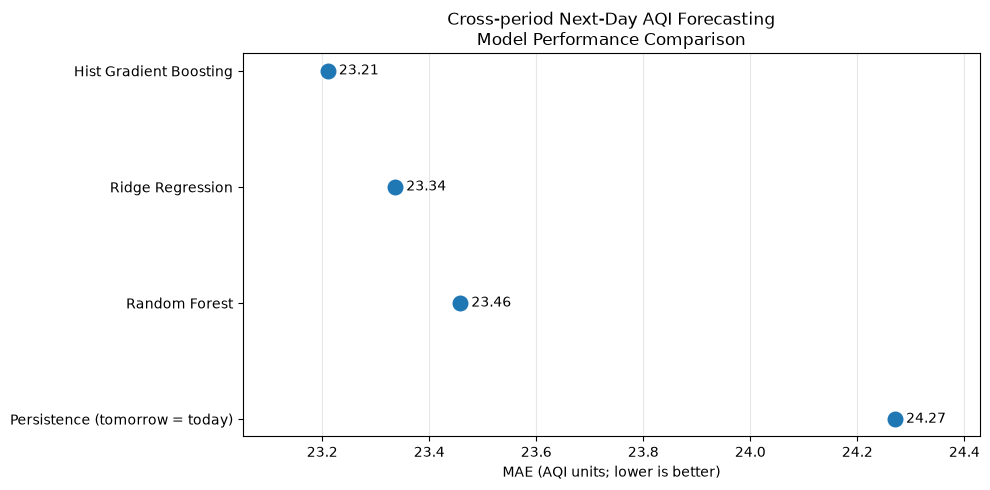

In [16]:
#=
# Create results table
cross_period_results = (
    pd.DataFrame(results)
    .sort_values('MAE')
    .reset_index(drop=True)
)

# Display evaluation results
display(cross_period_results.round(3))

# Save CSV results
cross_period_results.to_csv(
    RESULTS / 'historical_model_results.csv',
    index=False
)

# Create MAE dot plot
fig, ax = plt.subplots(figsize=(10, 5))

models = cross_period_results['Model']
mae_values = cross_period_results['MAE']

y = range(len(models))

ax.scatter(
    mae_values,
    y,
    s=110,
    zorder=3
)

# Add MAE labels beside points
for i, value in enumerate(mae_values):
    ax.annotate(
        f'{value:.2f}',
        (value, i),
        xytext=(8, 0),
        textcoords='offset points',
        va='center'
    )

ax.set_yticks(list(y))
ax.set_yticklabels(models)
ax.invert_yaxis()

ax.set_xlabel('MAE (AQI units; lower is better)')
ax.set_title(
    'Cross-period Next-Day AQI Forecasting\n'
    'Model Performance Comparison'
)

ax.grid(axis='x', alpha=0.3)

# Leave room for point labels
ax.margins(x=0.15)

fig.tight_layout()

# Save PNG (replaces old bar graph)
fig.savefig(
    FIGURES / 'cross_period_mae.png',
    dpi=160,
    bbox_inches='tight'
)

plt.show()

## 8. Prediction Diagnostics and City-Wise Evaluation

Actual-versus-predicted plots, city-level MAE comparisons, and individual forecasting trajectories are used to examine prediction reliability.

The analysis compares the best historical-trained model with persistence across the 23 test cities, highlighting geographic differences in forecasting difficulty.

Separate time-series plots for **Delhi, Chandigarh, and Mumbai** illustrate how closely predictions follow observed AQI changes during the held-out period.

City-level MAE should be interpreted alongside differences in AQI variability and the number of available test observations.

Best historical model: Historical - Hist Gradient Boosting


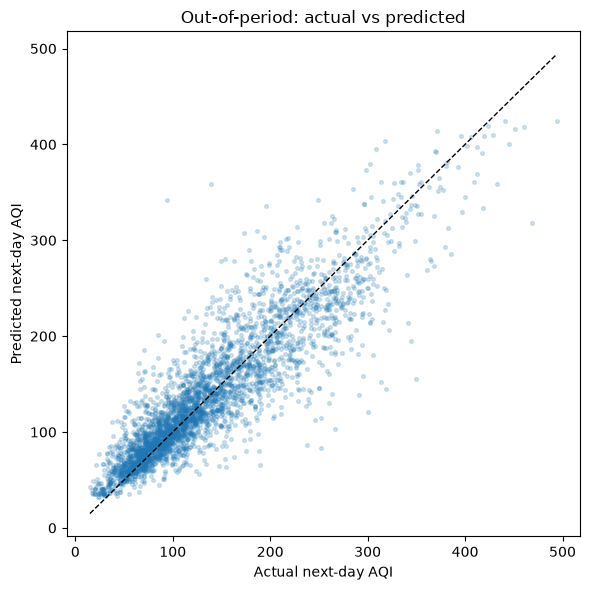

,City,n,Historical_MAE,Persistence_MAE
13,Hyderabad,175,7.58,7.81
4,Bengaluru,175,10.34,10.46
1,Aizawl,145,12.96,11.62
17,Mumbai,175,13.59,14.31
8,Chennai,175,15.11,15.21
2,Amaravati,148,18.96,19.88
9,Coimbatore,169,19.04,20.03
6,Brajrajnagar,113,19.20,19.49
15,Kolkata,175,21.10,21.81
5,Bhopal,175,21.99,24.53


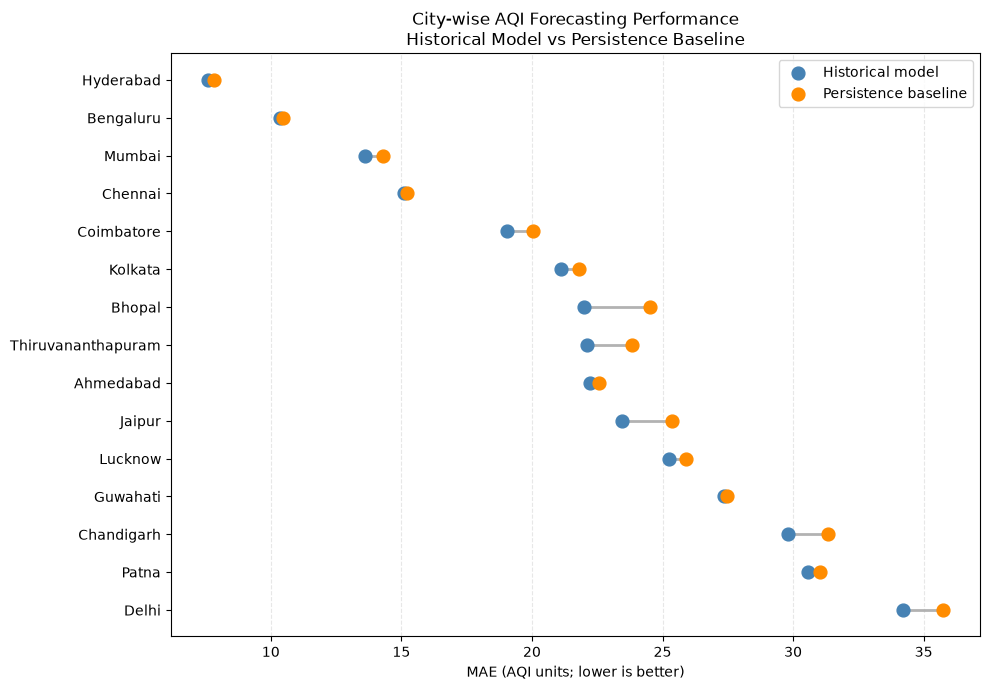

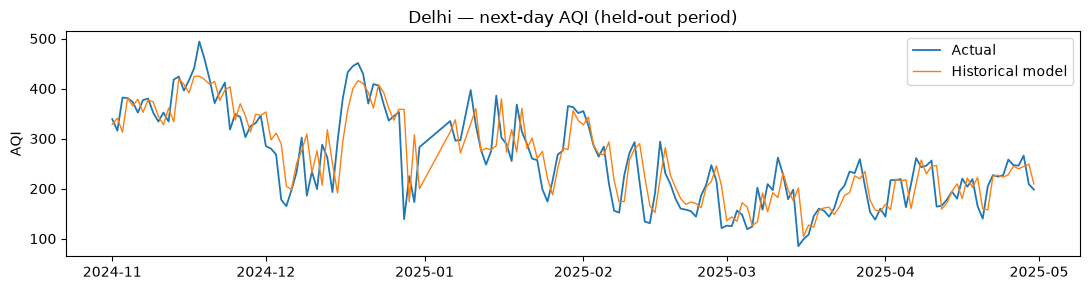

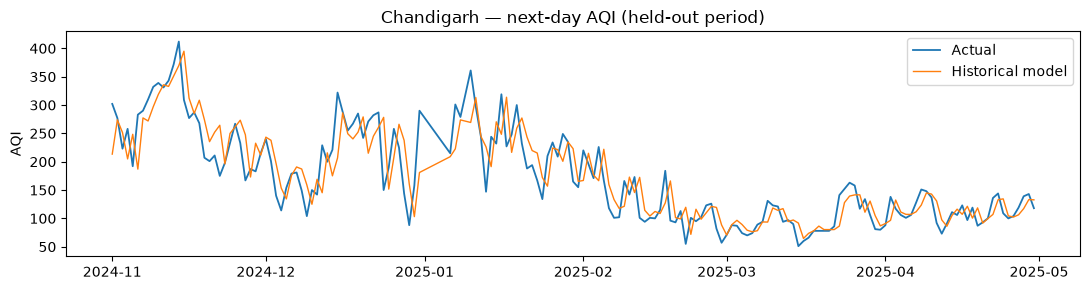

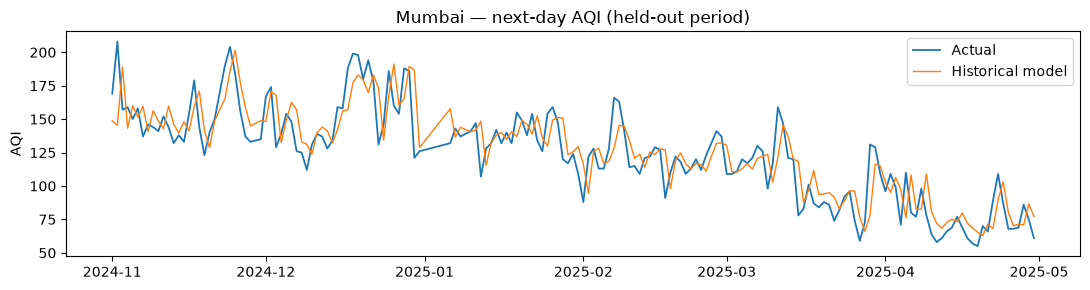

In [ ]:


best_historical_name = min(
    [x for x in predictions.columns if x.startswith('Historical - ')],
    key=lambda x: mean_absolute_error(actual, predictions[x])
)

print('Best historical model:', best_historical_name)



fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    actual,
    predictions[best_historical_name],
    s=7,
    alpha=0.2
)

limits = (
    min(actual.min(), predictions[best_historical_name].min()),
    max(actual.max(), predictions[best_historical_name].max())
)

ax.plot(limits, limits, 'k--', lw=1)

ax.set(
    xlabel='Actual next-day AQI',
    ylabel='Predicted next-day AQI',
    title='Out-of-period: actual vs predicted'
)

fig.tight_layout()

fig.savefig(
    FIGURES / 'actual_vs_predicted.png',
    dpi=160
)

plt.show()



city_rows = []

for city, g in predictions.groupby('City'):

    if len(g) < 10:
        continue

    city_rows.append({
        'City': city,
        'n': len(g),
        'Historical_MAE': mean_absolute_error(
            g.actual,
            g[best_historical_name]
        ),
        'Persistence_MAE': mean_absolute_error(
            g.actual,
            g['Persistence']
        )
    })

city_scores = (
    pd.DataFrame(city_rows)
    .sort_values('Historical_MAE')
)

display(city_scores.head(15).round(2))

# Save city-wise results
city_scores.to_csv(
    RESULTS / 'city_wise_errors.csv',
    index=False
)




if len(city_scores):

    # Select 15 cities with the most test observations
    show = (
        city_scores
        .sort_values('n', ascending=False)
        .head(15)
        .sort_values('Historical_MAE')
        .reset_index(drop=True)
    )

    y = np.arange(len(show))

    fig, ax = plt.subplots(figsize=(10, 7))

    # Connect historical and persistence MAE values
    for i, row in show.iterrows():

        ax.plot(
            [
                row['Historical_MAE'],
                row['Persistence_MAE']
            ],
            [i, i],
            color='gray',
            linewidth=2,
            alpha=0.6,
            zorder=1
        )

    # Historical model markers
    ax.scatter(
        show['Historical_MAE'],
        y,
        s=85,
        color='steelblue',
        label='Historical model',
        zorder=3
    )

    # Persistence baseline markers
    ax.scatter(
        show['Persistence_MAE'],
        y,
        s=85,
        color='darkorange',
        label='Persistence baseline',
        zorder=3
    )

    # Axis formatting
    ax.set_yticks(y)
    ax.set_yticklabels(show['City'])
    ax.invert_yaxis()

    ax.set_xlabel(
        'MAE (AQI units; lower is better)'
    )

    ax.set_title(
        'City-wise AQI Forecasting Performance\n'
        'Historical Model vs Persistence Baseline'
    )

    ax.grid(
        axis='x',
        linestyle='--',
        alpha=0.3
    )

    ax.legend()

    fig.tight_layout()

    # Save with the original filename
    # This overwrites the previous bar-chart PNG
    fig.savefig(
        FIGURES / 'city_wise_mae.png',
        dpi=160,
        bbox_inches='tight'
    )

    plt.show()




for city in ['Delhi', 'Chandigarh', 'Mumbai']:

    sample = (
        predictions[predictions.City == city]
        .sort_values('target_date')
    )

    if sample.empty:
        print(city, 'not present in common test cities')
        continue

    fig, ax = plt.subplots(figsize=(11, 3))

    # Actual AQI
    ax.plot(
        sample.target_date,
        sample.actual,
        label='Actual',
        lw=1.3
    )

    # Historical model prediction
    ax.plot(
        sample.target_date,
        sample[best_historical_name],
        label='Historical model',
        lw=1
    )

    ax.set(
        title=f'{city} — next-day AQI (held-out period)',
        ylabel='AQI'
    )

    ax.legend()

    fig.tight_layout()

    fig.savefig(
        FIGURES / f'forecast_{city.lower()}.png',
        dpi=160
    )

    plt.show()


## 9. Historical Versus Recent Training

Models trained on historical and recent observations are compared on the same **3,604 held-out observations**, using identical feature definitions.

| Model | Historical MAE | Recent MAE |
|---|---:|---:|
| Ridge Regression | 23.336 | 23.090 |
| Random Forest | 23.458 | 23.532 |
| Histogram Gradient Boosting | 23.210 | 23.313 |

Recent-trained Ridge Regression achieves the lowest overall MAE (**23.090**), while historical-trained Histogram Gradient Boosting achieves **23.210**.

The differences are relatively small. Historical training slightly improves Random Forest and Histogram Gradient Boosting performance, whereas recent training improves Ridge Regression.

These results suggest that historical AQI patterns retain predictive value on recent observations, although performance depends on the model and training distribution.

Completed recent: Ridge Regression
Completed recent: Random Forest
Completed recent: Hist Gradient Boosting


,Training,Model,MAE,RMSE,R2
0,Historical 2015–2020,Hist Gradient Boosting,23.210,33.363,0.800
1,Recent pre-test (2023–2024),Hist Gradient Boosting,23.313,33.660,0.796
2,No fitting,Persistence (tomorrow = today),24.270,35.826,0.769
3,Historical 2015–2020,Random Forest,23.458,33.569,0.797
4,Recent pre-test (2023–2024),Random Forest,23.532,33.935,0.793
5,Historical 2015–2020,Ridge Regression,23.336,33.477,0.798
6,Recent pre-test (2023–2024),Ridge Regression,23.090,33.119,0.802


Training,Historical 2015–2020,Recent pre-test (2023–2024)
Model,,
Hist Gradient Boosting,23.210,23.313
Random Forest,23.458,23.532
Ridge Regression,23.336,23.090


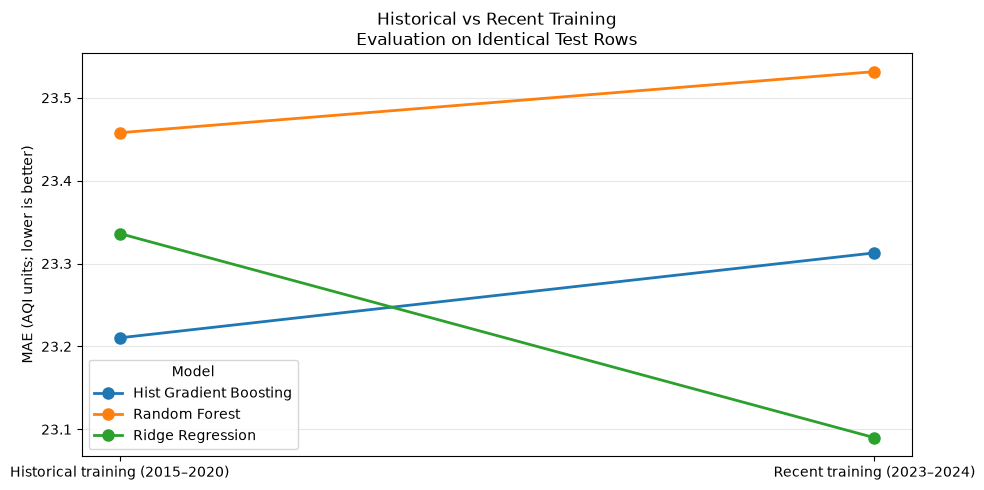

Test rows: 3604 | cities: 23

Historical AQI distribution:


count    20112.0
mean       148.0
std         96.7
min         14.0
25%         79.0
50%        114.0
75%        187.0
max        499.0
Name: AQI, dtype: float64


Recent training AQI distribution:


count    12753.0
mean       110.6
std         69.6
min          7.0
25%         62.0
50%         91.0
75%        138.0
max        468.0
Name: AQI, dtype: float64


Test AQI distribution:


count    3604.0
mean      136.5
std        74.6
min        12.0
25%        81.0
50%       118.0
75%       178.0
max       494.0
Name: AQI, dtype: float64

In [ ]:


# 1. Train models on recent data
recent_fitted = {}

for name, model in make_models().items():

    model.fit(
        recent_train[FEATURES],
        recent_train['target_AQI_next']
    )

    p = model.predict(test[FEATURES])

    predictions['Recent - ' + name] = p

    results.append(
        evaluate(actual, p, name, 'Recent pre-test (2023–2024)')
    )

    recent_fitted[name] = model

    print('Completed recent:', name)


# 2. Combine historical and recent results
comparison = (
    pd.DataFrame(results)
    .sort_values(['Model', 'Training'])
    .reset_index(drop=True)
)

display(comparison.round(3))


# 3. Save evaluation results
comparison.to_csv(
    RESULTS / 'all_models_same_test_results.csv',
    index=False
)

predictions.to_csv(
    RESULTS / 'predictions_same_test_rows.csv',
    index=False
)


# 4. Prepare matched model comparison
paired = (
    comparison[comparison['Training'] != 'No fitting']
    .pivot(
        index='Model',
        columns='Training',
        values='MAE'
    )
)

display(paired.round(3))


# 5. Create slope chart instead of grouped bar chart
if paired.shape[1] >= 2:

    # Explicit order: historical first, recent second
    historical_col = next(
        c for c in paired.columns
        if 'Historical' in c
    )

    recent_col = next(
        c for c in paired.columns
        if 'Recent' in c
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    for model_name, row in paired.iterrows():

        values = [
            row[historical_col],
            row[recent_col]
        ]

        ax.plot(
            [0, 1],
            values,
            marker='o',
            markersize=8,
            linewidth=2,
            label=model_name
        )

    ax.set_xticks([0, 1])

    ax.set_xticklabels([
        'Historical training (2015–2020)',
        'Recent training (2023–2024)'
    ])

    ax.set_ylabel(
        'MAE (AQI units; lower is better)'
    )

    ax.set_title(
        'Historical vs Recent Training\n'
        'Evaluation on Identical Test Rows'
    )

    ax.grid(axis='y', alpha=0.3)
    ax.legend(title='Model')

    fig.tight_layout()

    # Overwrite the previous grouped bar-chart PNG
    fig.savefig(
        FIGURES / 'historical_vs_recent_mae.png',
        dpi=160,
        bbox_inches='tight'
    )

    plt.show()


# 6. Display data coverage
print(
    'Test rows:', len(test),
    '| cities:', test['City'].nunique()
)

print('\nHistorical AQI distribution:')
display(historical_train['AQI'].describe().round(1))

print('\nRecent training AQI distribution:')
display(recent_train['AQI'].describe().round(1))

print('\nTest AQI distribution:')
display(test['AQI'].describe().round(1))

## 10. Summary and Conclusion

This experiment evaluates the transferability of historical AQI forecasting models to recent observations using a consistent feature schema and a common held-out test cohort.

### Key Findings

1. **Cross-period performance:** Historical-trained Histogram Gradient Boosting achieves an MAE of **23.210**, RMSE of **33.363**, and R² of **0.800**, outperforming the persistence MAE of **24.270**.

2. **Matched training-period comparison:** Recent-trained Ridge Regression produces the lowest overall MAE (**23.090**). However, historical-trained Histogram Gradient Boosting performs slightly better than its recent-trained counterpart (**23.210 versus 23.313**).

3. **Limited performance differences:** The small differences between historical and recent training suggest that historical AQI patterns remain relevant for next-day forecasting, but there is no consistent advantage to either training period across all models.

4. **Geographic variation:** City-level prediction errors differ substantially. Mumbai achieves an MAE of approximately **13.59** using the best historical-trained model, while other cities experience greater forecasting difficulty.

5. **Data distribution differences:** Mean AQI is **148.0** in historical training, **110.6** in recent training, and **136.5** in the test cohort. These differences indicate that the datasets are not identically distributed.

### Limitations

- The comparison covers only 23 overlapping cities and 3,604 held-out observations.
- Historical and recent training datasets differ in size, geographic coverage, and AQI distributions.
- The experiment excludes pollutant concentrations and meteorological measurements.
- Predictions represent rolling **one-day-ahead forecasts**, assuming current-day AQI is available before forecasting the next day.
- Observed performance differences cannot independently establish the effects of changing pollution patterns, monitoring practices, or other external factors.

### Conclusion

Historical AQI-only models demonstrate useful predictive performance when transferred to recent observations. On the matched test cohort, all evaluated machine-learning models outperform persistence, but neither historical nor recent training consistently dominates across algorithms.

The experiment supports the value of historical AQI data while highlighting the importance of matched evaluation, temporal alignment, and simple forecasting baselines.

The exported metrics and predictions are incorporated into the final project comparison.